# A standard New Keynesian model with endogenous inflation

The time-to-produce notebooks in this folder have no Phillips curve: inflation is pinned
mechanically by $\pi_t = -\Delta a_t$, so a lower nominal rate has **no inflationary cost**.
That is why the planner problems corner at $i_t = 0$ and stay there — cutting rates buys
productivity through $\beta^\tau$ in `tprod` and nothing pushes back.

This notebook adds the missing block. It is the textbook three-equation model:

$$x_t = x_{t+1} - \tfrac{1}{\gamma}\bigl(i_t - \pi_{t+1} - r^n_t\bigr) \qquad\text{(IS)}$$
$$\pi_t = \beta\,\pi_{t+1} + \kappa\,x_t \qquad\text{(NKPC)}$$
$$i_t = \rho + \phi_\pi \pi_t + \phi_x x_t \qquad\text{(policy)}$$

Now a rate held below the natural rate raises the gap, the gap raises inflation, expected
inflation feeds back into the IS curve, and the whole thing compounds. Hold the rate too
low for too long and inflation **rises and rises**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
from scipy.optimize import minimize

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Calibration

$\gamma$, $\eta$ and $\sigma$ are carried over from the other notebooks. The one new
parameter is the slope of the Phillips curve. Rather than pick a Calvo $\theta$ out of
the air, it is matched to the **same mean price duration** implied by the time-to-produce
calibration, so this model and the $\tau$ model are talking about the same stickiness:

$$\theta = 1 - \frac{1}{\bar\tau}, \qquad
  \lambda = \frac{(1-\theta)(1-\beta\theta)}{\theta}, \qquad
  \kappa = \lambda(\gamma+\eta)$$

In [2]:
INVENTORY_TO_COGS_SCALING = 36.5
data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = (data['invtCogsRatio'] * INVENTORY_TO_COGS_SCALING / (30 * 0.1))

beta = 1 / (1.0 + 0.01)
beta1 = 1 / (1.0 + 0.01 * np.exp(30 / (INVENTORY_TO_COGS_SCALING * 0.9)))
rho = 1 / beta - 1

gamma = 2.0        # relative risk aversion / IS slope
eta = 2.0          # inverse Frisch elasticity
sigma = 5          # CES elasticity across firms (the demand elasticity, 'epsilon')

# --- recover the time-to-produce tau distribution, purely to calibrate the NKPC slope ---
tau_diff = np.zeros(1000)
for i, c in enumerate(np.linspace(0, 0.99, 1000)):
    if beta * c <= 1e-10:
        tau_diff[i] = np.inf
        continue
    N = -(data_tau) - 1/np.log(beta * c)
    t1 = -1/np.log(beta * c) - N;  t1[t1 < 0] = 0
    t2 = -1/np.log(beta1 * c) - N; t2[t2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(t1 - t2))
cval = np.linspace(0, 0.99, 1000)[np.argmin(np.abs(tau_diff - 1))]

N = -data_tau - 1/np.log(beta * cval)
tau = -1/np.log(beta * cval) - N
tau[tau < 0] = 0
tf, tc = np.floor(tau), np.ceil(tau)
pc = (beta * cval)**tc * (tc + N); pf = (beta * cval)**tf * (tf + N)
tau[(pc - pf) > 0] = tc[(pc - pf) > 0]
tau[(pc - pf) < 0] = tf[(pc - pf) < 0]
tau[tau < 0] = 0

mean_tau = float(tau.mean())
theta = 1 - 1/mean_tau                       # Calvo non-reset probability
lam = (1 - theta) * (1 - beta * theta) / theta
kappa = lam * (gamma + eta)                  # NKPC slope

print(f'mean time to produce      : {mean_tau:.4f} periods')
print(f'implied Calvo theta       : {theta:.4f}')
print(f'lambda                    : {lam:.4f}')
print(f'NKPC slope kappa          : {kappa:.4f}')
print(f'rho                       : {rho:.6f}')

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_56547/924099719.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


mean time to produce      : 2.8885 periods
implied Calvo theta       : 0.6538
lambda                    : 0.1868
NKPC slope kappa          : 0.7470
rho                       : 0.010000


## 2. Solving the model

Perfect foresight, terminal conditions $x_T = \pi_T = 0$, solved backward. Substituting the
IS curve into the NKPC gives the backward recursion

$$\begin{pmatrix}x_t\\ \pi_t\end{pmatrix} =
  \underbrace{\begin{pmatrix}1 & 1/\gamma\\ \kappa & \beta+\kappa/\gamma\end{pmatrix}}_{M}
  \begin{pmatrix}x_{t+1}\\ \pi_{t+1}\end{pmatrix}
  - \begin{pmatrix}1/\gamma\\ \kappa/\gamma\end{pmatrix}(i_t - r^n_t)$$

**The eigenvalues of $M$ are what drive everything below.** If the largest exceeds one, each
extra period of holding $i$ away from $r^n$ multiplies the initial response by that factor —
the inflation spiral.

In [3]:
def nk_solve(i_path, r_nat, kappa=kappa, gamma=gamma, beta=beta):
    """
    Perfect-foresight solution of the 3-equation NK model given an exogenous rate path.
    Terminal conditions x_T = pi_T = 0.  Returns (x, pi).
    """
    i_path = np.asarray(i_path, float)
    r_nat = np.asarray(r_nat, float)
    T = len(i_path)
    x = np.zeros(T + 1)
    pi = np.zeros(T + 1)
    for t in range(T - 1, -1, -1):
        x[t] = x[t+1] + (1.0/gamma) * (pi[t+1] - (i_path[t] - r_nat[t]))
        pi[t] = beta * pi[t+1] + kappa * x[t]
    return x[:T], pi[:T]


def nk_taylor(r_nat, phi_pi, phi_x=0.0, kappa=kappa, gamma=gamma, beta=beta, rho=rho):
    """
    Same model but with the rate set by a Taylor rule i_t = rho + phi_pi*pi_t + phi_x*x_t.
    Solved backward; substituting the rule makes each step a 2x2 linear solve.
    """
    T = len(r_nat)
    x = np.zeros(T + 1); pi = np.zeros(T + 1); i_path = np.zeros(T)
    for t in range(T - 1, -1, -1):
        # unknowns (x_t, pi_t) given (x_{t+1}, pi_{t+1}):
        #   x_t = x_{t+1} + (1/g)(pi_{t+1} - (rho + phi_pi*pi_t + phi_x*x_t - r_nat_t))
        #   pi_t = beta*pi_{t+1} + kappa*x_t
        A = np.array([[1 + phi_x/gamma, phi_pi/gamma], [-kappa, 1.0]])
        b = np.array([x[t+1] + (1.0/gamma)*(pi[t+1] - (rho - r_nat[t])), beta*pi[t+1]])
        sol = np.linalg.solve(A, b)
        x[t], pi[t] = sol
        i_path[t] = rho + phi_pi*pi[t] + phi_x*x[t]
    return x[:T], pi[:T], i_path


M = np.array([[1, 1/gamma], [kappa, beta + kappa/gamma]])
ev = np.linalg.eigvals(M)
print('backward recursion matrix M:\n', np.round(M, 4))
print('eigenvalues              :', np.round(ev, 4))
print(f'largest |eigenvalue|     : {max(abs(ev)):.4f}')
print('  -> every extra period of holding i away from r^n multiplies the initial')
print(f'     response by about {max(abs(ev)):.3f}x')

backward recursion matrix M:
 [[1.     0.5   ]
 [0.747  1.3636]]
eigenvalues              : [0.5442 1.8194]
largest |eigenvalue|     : 1.8194
  -> every extra period of holding i away from r^n multiplies the initial
     response by about 1.819x


## 3. The headline: hold the rate too low and inflation rises and rises

The natural rate is flat at $\rho$. Policy pegs $i_t = 0$ — a full percentage point below
$r^n$ — for the first $L$ periods, then returns to $\rho$. The only thing that changes
across runs is $L$.

In [4]:
T = 80
r_nat = np.ones(T) * rho
PEG = 0.0                                    # the too-low rate

rows = []
for L in range(1, 15):
    i_path = np.ones(T) * rho
    i_path[:L] = PEG
    x, pi = nk_solve(i_path, r_nat)
    rows.append((L, pi[0], x[0]))

print(f'{"peg length L":>13} {"pi_0 (%)":>14} {"x_0 (%)":>14} {"ratio to L-1":>14}')
print('-' * 60)
prev = None
for L, p0, x0 in rows:
    r = f'{p0/prev:.4f}' if prev else '--'
    print(f'{L:>13} {100*p0:>14.4f} {100*x0:>14.4f} {r:>14}')
    prev = p0

print()
print(f'largest eigenvalue of M            : {max(abs(ev)):.4f}')
print(f'observed per-period amplification  : {rows[-1][1]/rows[-2][1]:.4f}')
print('  -> they match: the spiral IS the unstable eigenvalue.')

 peg length L       pi_0 (%)        x_0 (%)   ratio to L-1
------------------------------------------------------------
            1         0.3735         0.5000             --
            2         1.2563         1.1868         3.3636
            3         2.9731         2.3149         2.3665
            4         6.1569         4.3015         2.0709
            5        11.9824         7.8799         1.9462
            6        22.5991        14.3711         1.8860
            7        41.9250        26.1707         1.8552
            8        77.0923        47.6332         1.8388
            9       141.0791        86.6793         1.8300
           10       257.4996       157.7189         1.8252
           11       469.3179       286.9687         1.8226
           12       854.7046       522.1276         1.8212
           13      1555.8847       949.9799         1.8204
           14      2831.6249      1728.4223         1.8199

largest eigenvalue of M            : 1.8194
observed 

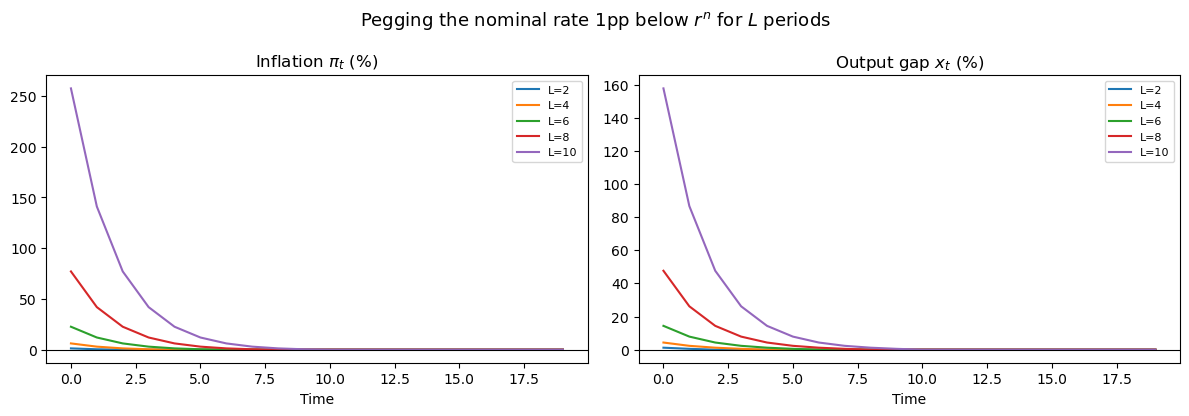

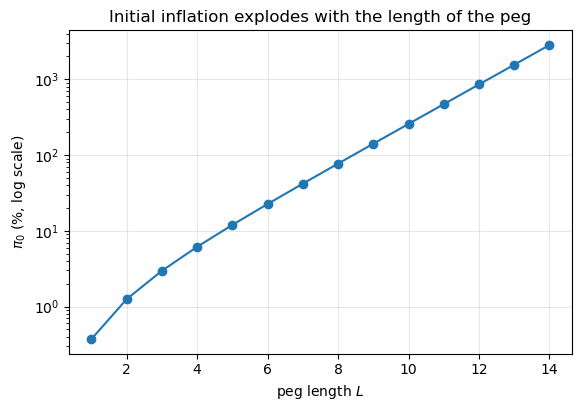

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for L in [2, 4, 6, 8, 10]:
    i_path = np.ones(T) * rho
    i_path[:L] = PEG
    x, pi = nk_solve(i_path, r_nat)
    axes[0].plot(100*pi[:20], label=f'L={L}')
    axes[1].plot(100*x[:20], label=f'L={L}')
axes[0].set_title('Inflation $\\pi_t$ (%)'); axes[0].set_xlabel('Time')
axes[0].axhline(0, color='k', lw=0.8); axes[0].legend(fontsize=8)
axes[1].set_title('Output gap $x_t$ (%)'); axes[1].set_xlabel('Time')
axes[1].axhline(0, color='k', lw=0.8); axes[1].legend(fontsize=8)
fig.suptitle('Pegging the nominal rate 1pp below $r^n$ for $L$ periods', fontsize=13)
plt.tight_layout()
plt.savefig('../semi_endo_nk_peg_spiral.png', dpi=150, bbox_inches='tight')
plt.show()

plt.figure(figsize=(6.5, 4.2))
plt.semilogy([r[0] for r in rows], [100*r[1] for r in rows], 'o-')
plt.xlabel('peg length $L$'); plt.ylabel('$\\pi_0$ (%, log scale)')
plt.title('Initial inflation explodes with the length of the peg')
plt.grid(True, alpha=0.3)
plt.savefig('../semi_endo_nk_peg_explosion.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Why: the Taylor principle

The spiral is not about the peg being *low*, it is about it not *responding*. Under
$i_t = \rho + \phi_\pi\pi_t$ the model is determinate when $\phi_\pi > 1$ and indeterminate
when $\phi_\pi < 1$. A peg is the limiting case $\phi_\pi = 0$.

One caveat on how this is checked. The backward solve above **always** returns finite
numbers, because the terminal condition $x_T=\pi_T=0$ pins the path down; you cannot read
determinacy off a simulated path. It has to be checked on the eigenvalues of the *forward*
system. Both $x$ and $\pi$ are jump variables, so determinacy requires **both** eigenvalues
outside the unit circle, which reproduces $\kappa(\phi_\pi-1)+(1-\beta)\phi_x>0$.

  phi_pi     |ev1|     |ev2|   determinate   max |pi_t| (%)    max |x_t| (%)
------------------------------------------------------------------------------
    0.00    1.8376    0.5496         False           6.1569           4.3015
    0.50    1.6691    0.7181         False           3.3679           1.9539
    0.90    1.4679    0.9194         False           2.2561           1.1095
    0.99    1.3967    0.9905         False           2.0788           0.9829
    1.01    1.0100    1.3772          True           2.0421           0.9570
    1.50    1.2553    1.2553          True           1.3714           0.5400
    2.00    1.3283    1.3283          True           0.9748           0.3901

this reproduces the textbook condition  kappa*(phi_pi - 1) + (1-beta)*phi_x > 0,
i.e. phi_pi > 1 when phi_x = 0 -- the Taylor principle.


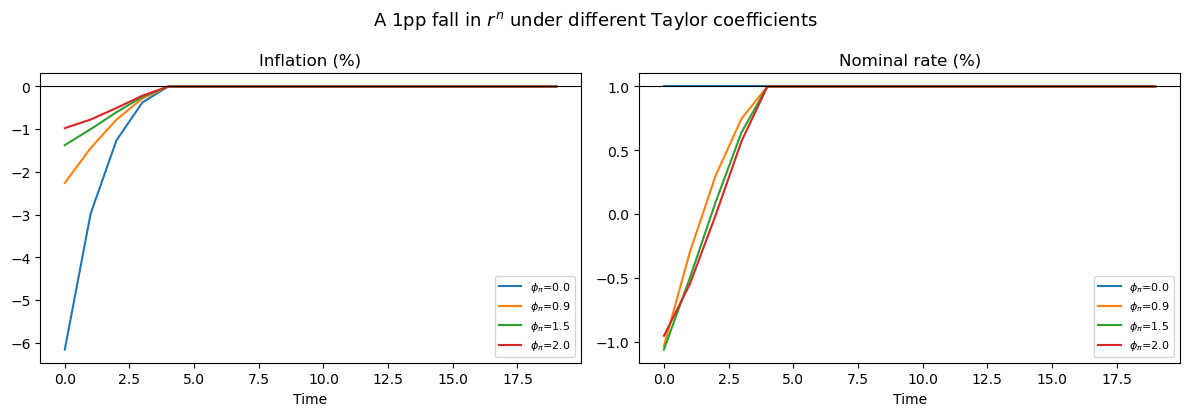

In [6]:
r_nat_shock = np.ones(T) * rho
r_nat_shock[:4] = rho - 0.01          # a 1pp, 4-period fall in the natural rate

# Determinacy must be judged on the FORWARD system, not on the simulated path: the
# backward solve always returns finite numbers because the terminal condition pins them.
# Both x and pi are jump variables, so determinacy requires BOTH eigenvalues outside
# the unit circle.
def determinacy(phi_pi, phi_x=0.0):
    A = np.array([[1 + phi_x/gamma + kappa/(gamma*beta), phi_pi/gamma - 1/(gamma*beta)],
                  [-kappa/beta, 1/beta]])
    return np.abs(np.linalg.eigvals(A))


print(f'{"phi_pi":>8} {"|ev1|":>9} {"|ev2|":>9} {"determinate":>13} '
      f'{"max |pi_t| (%)":>16} {"max |x_t| (%)":>16}')
print('-' * 78)
for phi_pi in [0.0, 0.5, 0.9, 0.99, 1.01, 1.5, 2.0]:
    x, pi, ip = nk_taylor(r_nat_shock, phi_pi)
    ev_a = determinacy(phi_pi)
    det = bool(np.all(ev_a > 1))
    print(f'{phi_pi:>8.2f} {ev_a[0]:>9.4f} {ev_a[1]:>9.4f} {str(det):>13} '
          f'{100*np.max(np.abs(pi)):>16.4f} {100*np.max(np.abs(x)):>16.4f}')

print()
print('this reproduces the textbook condition  kappa*(phi_pi - 1) + (1-beta)*phi_x > 0,')
print('i.e. phi_pi > 1 when phi_x = 0 -- the Taylor principle.')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for phi_pi in [0.0, 0.9, 1.5, 2.0]:
    x, pi, ip = nk_taylor(r_nat_shock, phi_pi)
    axes[0].plot(100*pi[:20], label=f'$\\phi_\\pi$={phi_pi}')
    axes[1].plot(100*ip[:20], label=f'$\\phi_\\pi$={phi_pi}')
axes[0].set_title('Inflation (%)'); axes[0].axhline(0, color='k', lw=0.8)
axes[0].set_xlabel('Time'); axes[0].legend(fontsize=8)
axes[1].set_title('Nominal rate (%)'); axes[1].axhline(100*rho, color='k', lw=0.8)
axes[1].set_xlabel('Time'); axes[1].legend(fontsize=8)
fig.suptitle('A 1pp fall in $r^n$ under different Taylor coefficients', fontsize=13)
plt.tight_layout()
plt.savefig('../semi_endo_nk_taylor_principle.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Optimal policy is now interior

This is the payoff. The welfare-based loss for this model is the second-order
approximation to household utility,

$$\mathcal{L} = \sum_t \beta^t\Bigl[(\gamma+\eta)\,x_t^2 + \frac{\varepsilon}{\lambda}\pi_t^2\Bigr]$$

with $\varepsilon = \sigma$ the demand elasticity. The $\pi^2$ term is exactly what the
time-to-produce notebooks lack. With it, cutting the rate is no longer free: the same
escalation that ran to the corner there now returns to $\rho$.

Two things to read carefully in the output below. First, the experiment is a pure
**natural-rate** shock, and this model has no trade-off against one — *divine coincidence*
— so the optimum drives the loss to (numerically) zero by simply setting $i_t = r^n_t$.
The losses at $L=4$ and $L=5$ are both zero to machine precision; the ordering between
them is optimiser noise, not economics. Second, that is why the rate returns to $\rho$ on
its own: $r^n$ itself returns to $\rho$ after four periods. To get a genuine
inflation-output trade-off you need a **cost-push** shock in the NKPC, which this notebook
does not include.

In [7]:
def welfare_loss(x, pi, gamma=gamma, eta=eta, sigma=sigma, lam=lam, beta=beta):
    T = len(x)
    disc = beta ** np.arange(T)
    return float(np.sum(disc * ((gamma + eta) * x**2 + (sigma / lam) * pi**2)))


r_nat_shock = np.ones(T) * rho
r_nat_shock[:4] = rho - 0.01          # same 1pp, 4-period natural-rate shock


def obj(r, L):
    i_path = np.ones(T) * rho
    i_path[:L] = r
    x, pi = nk_solve(i_path, r_nat_shock)
    return welfare_loss(x, pi)


print(f'{"L":>3} {"last i_t":>11} {"settled":>8} {"loss":>14}   optimal sequence')
print('-' * 88)
for L in range(3, 13):
    res = minimize(lambda r: obj(r, L), np.ones(L) * rho, method='L-BFGS-B',
                   bounds=[(0.0, 0.05)] * L,
                   options={'maxiter': 20000, 'ftol': 1e-18, 'gtol': 1e-14})
    settled = bool(np.isclose(res.x[-1], rho, atol=1e-4))
    print(f'{L:>3} {res.x[-1]:>11.6f} {str(settled):>8} {res.fun:>14.6e}   '
          f'{np.round(res.x[:8], 5)}{" ..." if L > 8 else ""}')
    if settled:
        print(f'\n-> settles at L = {L}: the rate comes back to rho = {rho:.4f}')
        r_star = res.x
        break
else:
    r_star = res.x
    print('\n-> did not settle')

  L    last i_t  settled           loss   optimal sequence
----------------------------------------------------------------------------------------
  3    0.000000    False   3.972512e-02   [0. 0. 0.]
  4    0.000000    False   1.050253e-31   [0. 0. 0. 0.]
  5    0.009999     True   1.580423e-12   [0.   0.   0.   0.   0.01]

-> settles at L = 5: the rate comes back to rho = 0.0100


loss, no policy change : 1.396026e-01
loss, optimal policy   : 1.580423e-12


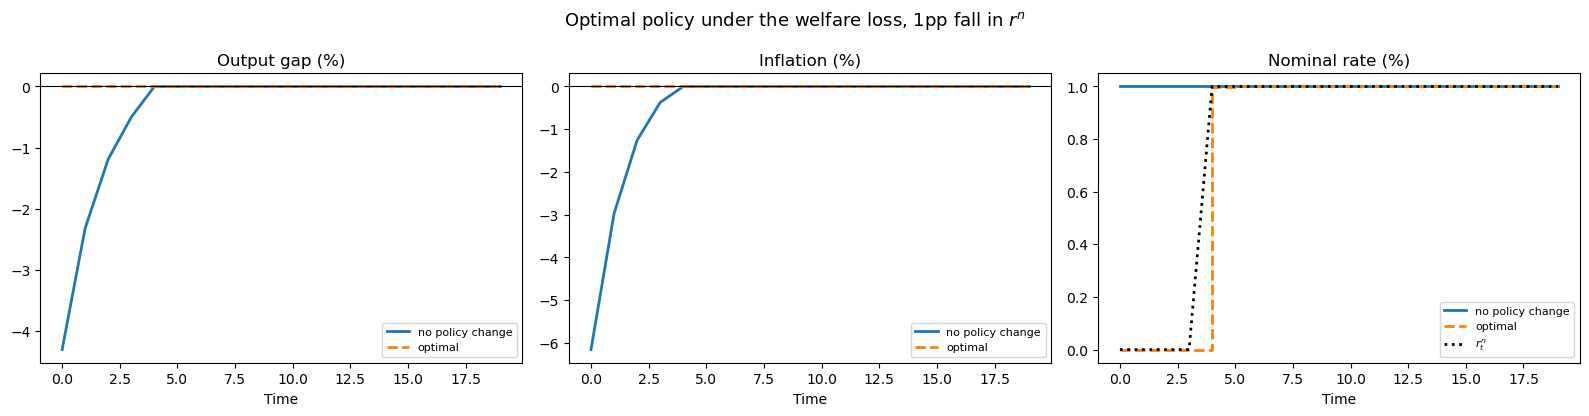

In [8]:
i_opt = np.ones(T) * rho; i_opt[:len(r_star)] = r_star
i_base = np.ones(T) * rho
x_o, pi_o = nk_solve(i_opt, r_nat_shock)
x_b, pi_b = nk_solve(i_base, r_nat_shock)

print(f'loss, no policy change : {welfare_loss(x_b, pi_b):.6e}')
print(f'loss, optimal policy   : {welfare_loss(x_o, pi_o):.6e}')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
h = 20
axes[0].plot(100*x_b[:h], lw=2, label='no policy change')
axes[0].plot(100*x_o[:h], '--', lw=2, label='optimal')
axes[0].axhline(0, color='k', lw=0.8); axes[0].set_title('Output gap (%)')
axes[0].set_xlabel('Time'); axes[0].legend(fontsize=8)

axes[1].plot(100*pi_b[:h], lw=2, label='no policy change')
axes[1].plot(100*pi_o[:h], '--', lw=2, label='optimal')
axes[1].axhline(0, color='k', lw=0.8); axes[1].set_title('Inflation (%)')
axes[1].set_xlabel('Time'); axes[1].legend(fontsize=8)

axes[2].step(np.arange(h), 100*i_base[:h], where='post', lw=2, label='no policy change')
axes[2].step(np.arange(h), 100*i_opt[:h], where='post', linestyle='--', lw=2, label='optimal')
axes[2].plot(100*r_nat_shock[:h], ':', color='k', lw=2, label='$r^n_t$')
axes[2].set_title('Nominal rate (%)'); axes[2].set_xlabel('Time'); axes[2].legend(fontsize=8)

fig.suptitle('Optimal policy under the welfare loss, 1pp fall in $r^n$', fontsize=13)
plt.tight_layout()
plt.savefig('../semi_endo_nk_optimal_policy.png', dpi=150, bbox_inches='tight')
plt.show()